Dataset shape: (569, 32)
Data Partitioning Summary:
Training set   : 398 samples (69.9%)
Validation set : 85 samples (14.9%)
Test set       : 86 samples (15.1%)

Class distribution (proportion of Malignant = 1):
Train : 0.372 | Val : 0.376 | Test : 0.372

--- Linear Regression (Baseline Numeric Fit) ---
Validation MSE      : 0.0581
Validation R2       : 0.7524
Threshold Accuracy  : 0.9647

--- Validation Performance Comparison ---
                       Model  Val Accuracy  Val Precision  Val Recall  Val F1-Score  Val ROC-AUC  Train 5-Fold F1
         Logistic Regression        0.9647         1.0000      0.9062        0.9508       0.9965           0.9757
               Random Forest        0.9647         1.0000      0.9062        0.9508       0.9941           0.9191
      Ensemble (Soft Voting)        0.9647         1.0000      0.9062        0.9508       0.9947           0.9614
Support Vector Machine (RBF)        0.9529         1.0000      0.8750        0.9333       0.9959           0.

/tmp/ipykernel_1043/3679062456.py:134: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=results_df, x="Val F1-Score", y="Model", palette="viridis")


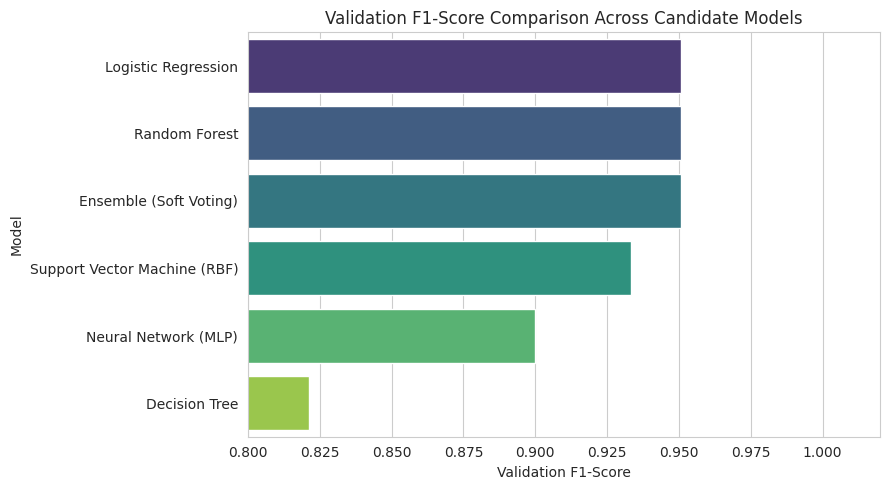


--- Final Test Set Evaluation (Logistic Regression) ---
Test Accuracy  : 0.9767
Test Precision : 0.9688
Test Recall    : 0.9688
Test F1-Score  : 0.9688
Test ROC-AUC   : 0.9988

Classification Report (Test Set):
               precision    recall  f1-score   support

   Benign (0)       0.98      0.98      0.98        54
Malignant (1)       0.97      0.97      0.97        32

     accuracy                           0.98        86
    macro avg       0.98      0.98      0.98        86
 weighted avg       0.98      0.98      0.98        86



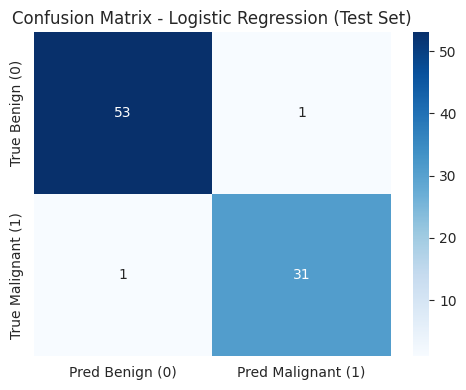

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, VotingClassifier, GradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, roc_auc_score,
    mean_squared_error, r2_score
)

# Make plots look cleaner
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (8, 5)
#%%
# Load the original UCI file.
# We use the direct URL so the notebook is reproducible without manual upload.

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/breast-cancer-wisconsin/wdbc.data"

# The original file has no header row, so we define column names manually.
columns = ['id', 'diagnosis'] + [f'feature_{i}' for i in range(1, 31)]
df = pd.read_csv(url, header=None, names=columns)

print("Dataset shape:", df.shape)
df.head()


# ============================================================
# Stage 2: Data Partitioning (Train / Validation / Test Split)
# ============================================================
# Note: Assumes Stage 1 produced `X_scaled` (features) and `y` (binary target: 0/1).
# If running standalone after the snippet above, ensure preprocessing (`X_scaled`, `y`)
# is executed first.

# First split: 70% Train, 30% Temp (to be split equally into 15% Validation and 15% Test)
X_train, X_temp, y_train, y_temp = train_test_split(
    X_scaled, y, test_size=0.30, random_state=42, stratify=y
)

# Second split: 50% of Temp -> 15% Validation, 15% Test of the full dataset
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

print("Data Partitioning Summary:")
print(f"Training set   : {X_train.shape[0]} samples ({X_train.shape[0]/len(X_scaled):.1%})")
print(f"Validation set : {X_val.shape[0]} samples ({X_val.shape[0]/len(X_scaled):.1%})")
print(f"Test set       : {X_test.shape[0]} samples ({X_test.shape[0]/len(X_scaled):.1%})")

print("\nClass distribution (proportion of Malignant = 1):")
print(f"Train : {y_train.mean():.3f} | Val : {y_val.mean():.3f} | Test : {y_test.mean():.3f}")


# ============================================================
# Stage 3: Model Selection, Training & Validation Comparison
# ============================================================

# 3.1 Baseline Linear Regression (continuous numeric fit on binary target for comparison)
lin_reg = LinearRegression()
lin_reg.fit(X_train, y_train)
y_val_lin_pred = lin_reg.predict(X_val)
y_val_lin_class = (y_val_lin_pred >= 0.5).astype(int)

print("\n--- Linear Regression (Baseline Numeric Fit) ---")
print(f"Validation MSE      : {mean_squared_error(y_val, y_val_lin_pred):.4f}")
print(f"Validation R2       : {r2_score(y_val, y_val_lin_pred):.4f}")
print(f"Threshold Accuracy  : {accuracy_score(y_val, y_val_lin_class):.4f}")

# 3.2 Candidate Classification Models
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Support Vector Machine (RBF)": SVC(kernel='rbf', probability=True, random_state=42),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "Neural Network (MLP)": MLPClassifier(
        hidden_layer_sizes=(64, 32), activation='relu',
        max_iter=500, early_stopping=True, random_state=42
    )
}

# Ensemble Learning Model (Soft Voting combining diverse classifiers)
ensemble_model = VotingClassifier(
    estimators=[
        ('lr', LogisticRegression(max_iter=1000, random_state=42)),
        ('svm', SVC(kernel='rbf', probability=True, random_state=42)),
        ('rf', RandomForestClassifier(n_estimators=100, random_state=42)),
        ('mlp', MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=500, early_stopping=True, random_state=42))
    ],
    voting='soft'
)
models["Ensemble (Soft Voting)"] = ensemble_model

# Train each model on X_train and evaluate on X_val
val_results = []
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for name, model in models.items():
    model.fit(X_train, y_train)
    y_val_pred = model.predict(X_val)
    y_val_prob = model.predict_proba(X_val)[:, 1]

    # Cross-validation F1 on training set for stability check
    cv_f1 = cross_val_score(model, X_train, y_train, cv=cv, scoring='f1').mean()

    val_results.append({
        "Model": name,
        "Val Accuracy": accuracy_score(y_val, y_val_pred),
        "Val Precision": precision_score(y_val, y_val_pred),
        "Val Recall": recall_score(y_val, y_val_pred),
        "Val F1-Score": f1_score(y_val, y_val_pred),
        "Val ROC-AUC": roc_auc_score(y_val, y_val_prob),
        "Train 5-Fold F1": cv_f1
    })

results_df = pd.DataFrame(val_results).sort_values(by="Val F1-Score", ascending=False)
print("\n--- Validation Performance Comparison ---")
print(results_df.round(4).to_string(index=False))

# Select the best-performing model based on Validation F1-Score
best_model_name = results_df.iloc[0]["Model"]
best_model = models[best_model_name]
print(f"\nSelected Best Model: {best_model_name}")

# Visualize Validation F1-Score across models
plt.figure(figsize=(9, 5))
sns.barplot(data=results_df, x="Val F1-Score", y="Model", palette="viridis")
plt.title("Validation F1-Score Comparison Across Candidate Models")
plt.xlabel("Validation F1-Score")
plt.ylabel("Model")
plt.xlim(0.8, 1.02)
plt.tight_layout()
plt.show()

# 3.3 Final Evaluation on Unseen Test Set
y_test_pred = best_model.predict(X_test)
y_test_prob = best_model.predict_proba(X_test)[:, 1]

print(f"\n--- Final Test Set Evaluation ({best_model_name}) ---")
print(f"Test Accuracy  : {accuracy_score(y_test, y_test_pred):.4f}")
print(f"Test Precision : {precision_score(y_test, y_test_pred):.4f}")
print(f"Test Recall    : {recall_score(y_test, y_test_pred):.4f}")
print(f"Test F1-Score  : {f1_score(y_test, y_test_pred):.4f}")
print(f"Test ROC-AUC   : {roc_auc_score(y_test, y_test_prob):.4f}")
print("\nClassification Report (Test Set):")
print(classification_report(y_test, y_test_pred, target_names=["Benign (0)", "Malignant (1)"]))

# Confusion Matrix on Test Set
cm = confusion_matrix(y_test, y_test_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Pred Benign (0)", "Pred Malignant (1)"],
    yticklabels=["True Benign (0)", "True Malignant (1)"]
)
plt.title(f"Confusion Matrix - {best_model_name} (Test Set)")
plt.tight_layout()
plt.show()